In [1]:
import os

# For headless MuJoCo rendering on a remote GPU server
os.environ["MUJOCO_GL"] = "egl"

# Cap CPU threads BEFORE numpy/torch are imported. These networks are tiny, so extra threads only add
# overhead, and on a shared node torch may otherwise start one thread per core of the whole machine.
# Override with the LDR_NUM_THREADS environment variable.
_avail = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
NUM_THREADS = int(os.environ.get("LDR_NUM_THREADS", min(4, _avail)))
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_v] = str(NUM_THREADS)

from dataclasses import dataclass, asdict
import numpy as np
import torch
import gymnasium as gym
import torch.nn as nn
from torch.distributions import Normal
import torch.nn.utils.parametrizations as param
from collections import deque
import torch.nn.functional as F
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from pathlib import Path
from IPython.display import Video, display
import pandas as pd
from pathlib import Path
import json
import mujoco
import random
import copy
import time
from scipy.special import gammaln

torch.set_num_threads(NUM_THREADS)
print(f"cores available to this process: {_avail} | machine cores: {os.cpu_count()} | "
      f"torch threads: {torch.get_num_threads()} | cuda: {torch.cuda.is_available()}")
from sklearn.metrics import adjusted_rand_score

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import r2_score, silhouette_score
import matplotlib.cm as cm



@dataclass
class LDRConfig:
    # SAC and training settings (Xu: configs/agents/hopper/ldr.yaml)
    total_timesteps: int = 1_500_000
    learning_starts: int = 0             # Xu: train_start_iterations = 0, policy acts from the start
    train_freq: int = 2048               # env steps collected per optimize() call
    gradient_steps: int = 2048           # gradient updates per optimize() call (1 per env step)
    batch_size: int = 256
    eval_interval: int = 100_000
    buffer_size: int = 1_000_000
    gamma: float = 0.99
    tau: float = 0.005
    learning_rate: float = 3e-4
    reward_scale: float = 0.008
    target_update_interval: int = 1
    hidden_dim: int = 256
    seed: int = 1012

    # LDR-specific settings
    n_past: int = 50
    latent_dim: int = 3                  # Xu uses 5 only for Ant
    vae_loss_weight: float = 5.0
    contrastive_loss_weight: float = 1.0
    infonce_temp: float = 1.0
    contrastive_start_iterations: int = 200_000   # Exp 3: encoder warm-up (RL + VAE only) before DP-Con
    latent_dropout_prob: float = 0.1
    min_positives: int = 1

    # KL annealing (Xu's kl_schedule): beta goes 0 -> beta_max linearly
    # over the first beta_anneal_fraction of training, then stays at beta_max
    beta_max: float = 0.1
    beta_anneal_fraction: float = 0.5
    
    # Experiment 3: DP-GMM cluster-aware contrastive learning
    ema_rho: float = 0.995               # teacher EMA momentum (rho)
    dp_refresh_interval: int = 100_000   # env steps between DP-GMM refreshes
    dp_num_points: int = 1500            # replay windows clustered per refresh
    dp_alpha: float = 1.0                # CRP concentration alpha_D
    dp_kappa0: float = 0.01              # NIW kappa_0
    dp_nu0: float = None                 # NIW nu_0 (None -> d_z + 2)
    dp_cluster_std: float = 0.3          # NIW Psi_0: prior within-cluster std (units of the global outcome std)
    dp_burn: int = 30                    # Gibbs burn-in sweeps
    dp_samples: int = 20                 # retained Gibbs samples (B in the write-up)
    dp_thin: int = 2                     # sweeps between retained samples
    dp_min_positive_mass: float = 0.5    # anchor valid if sum_{l!=i} S_il exceeds this

    # Experiment 3.1: cluster in OUTCOME space (teacher-decoder predictions on shared probes), not on z
    num_probes: int = 64                 # M shared (s, a) reference pairs, resampled at each DP-GMM refresh
    outcome_pca_dim: int = 4             # PCA dims of the (M * obs_dim) outcome vector fed to the DP-GMM
    outcome_chunk: int = 256             # histories per teacher-decoder pass when building y_i
    encoder_reg_mode: str = "none" #specify "none", "l2", or "spectral" or "orthogonal" for encoder regularization

cores available to this process: 4 | machine cores: 128 | torch threads: 4 | cuda: False


In [2]:
def applyLipschitzRegularization(module, reg_mode):
    """Recursively apply spectral/orthogonal parametrization to Linear and Conv1d children (Xu)."""
    if reg_mode not in ("spectral", "orthogonal", "none"):
        raise ValueError(f"Invalid reg_mode '{reg_mode}'")
    if reg_mode == "none":
        return module
    for child in module.children():
        if isinstance(child, (nn.Linear, nn.Conv1d)):
            if reg_mode == "spectral":
                param.spectral_norm(child, name="weight")
            else:
                param.orthogonal(child, name="weight")
        else:
            applyLipschitzRegularization(child, reg_mode)
    return module

In [3]:
class HistoryQueue:
    def __init__(self, n_envs, n_past, obs_dim, action_dim):
        self.n_envs, self.H, self.obs_dim, self.action_dim = n_envs, n_past, obs_dim, action_dim
        self.data = np.zeros((n_envs, n_past, obs_dim + action_dim), dtype=np.float32)
    
    def get(self):
        return self.data.copy()
    
    def append(self, obs, actions):
        # shifting all data except the last 1 row. then add the new obs and actions to the first row
        self.data[:,1:] = self.data[:,:-1].copy()
        self.data[:,0,:self.obs_dim] = obs
        self.data[:,0,self.obs_dim:] = actions
    
    # def reset_done(self, dones):
    #     self.data[np.asarray(dones, dtype=bool)] = 0

    def reset_done(self, dones, initial_obs):
        dones = np.asarray(dones, dtype=bool)
        self.data[dones] = 0
        if initial_obs is not None:
            self.data[dones, :, :self.obs_dim] = initial_obs[dones][:, None, :]


In [4]:
# Need to send latent_dim from the LDRAgent

class Actor(nn.Module):

    def __init__(self, obs_dim, action_dim, hidden_dim=256, latent_dim=0):
        super().__init__()
        self.latent_dim = latent_dim
        if latent_dim > 0:
            self.latent_norm = nn.LayerNorm(latent_dim)

        # Shared feature extractor
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )

        # Gaussian distribution parameters
        self.mu = nn.Linear(hidden_dim, action_dim)
        self.log_std = nn.Linear(hidden_dim, action_dim)
        self.log_std_min = -20
        self.log_std_max = 2

    def forward(self, obs):
        # obs = [env_obs, z]; normalize z before the MLP
        if self.latent_dim > 0:
            s, z = obs[..., :-self.latent_dim], obs[..., -self.latent_dim:]
            obs = torch.cat([s, self.latent_norm(z)], dim=-1)

        features = self.net(obs)
        mean = self.mu(features)
        log_std = self.log_std(features)
        log_std = torch.clamp(log_std, self.log_std_min, self.log_std_max)  
        std = log_std.exp()

        return mean, std


    # Sample actions and compute log probabilities
    def actionLogProb(self, obs):

        mean, std = self.forward(obs)
        dist = Normal(mean, std)
        u = dist.rsample() # reparameterization trick for backpropagation
        action = torch.tanh(u) # action between -1 and 1

        # Calculting log \pi(a|S)
        log_prob = dist.log_prob(u)
        log_prob -= 2 * (torch.log(torch.tensor(2.0, device=u.device)) - u - nn.functional.softplus(-2 * u))
        log_prob = log_prob.sum(dim=-1, keepdim=True)

        return action, log_prob

    def predict(self, obs, deterministic=True):
        """Return normalized actions for inference."""

        mean, std = self.forward(obs)

        if deterministic:
            return torch.tanh(mean)

        dist = Normal(mean, std)
        return torch.tanh(dist.sample())


In [5]:
class Critic(nn.Module):

    def __init__(self, obs_dim, action_dim, hidden_dim=256, latent_dim=0):
        super().__init__()

        input_dim = obs_dim + action_dim
        self.latent_dim = latent_dim

        # First Q network
        self.q1 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

        # Second Q network
        self.q2 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

        # One LayerNorm per Q head (Xu deep-copies the extractor for each head)
        if latent_dim > 0:
            self.norm1 = nn.LayerNorm(latent_dim)
            self.norm2 = nn.LayerNorm(latent_dim)

    def _input(self, obs, action, norm):
        if self.latent_dim > 0:
            s, z = obs[..., :-self.latent_dim], obs[..., -self.latent_dim:]
            obs = torch.cat([s, norm(z)], dim=-1)
        return torch.cat([obs, action], dim=-1)

    def forward(self, obs, action):
        if self.latent_dim > 0:
            q1 = self.q1(self._input(obs, action, self.norm1))
            q2 = self.q2(self._input(obs, action, self.norm2))
        else:
            x = torch.cat([obs, action], dim=-1)
            q1, q2 = self.q1(x), self.q2(x)

        return q1, q2



In [6]:
class ReplayBuffer:

    def __init__(self, buffer_size, num_envs, obs_dim, action_dim, device, n_past):

        self.num_envs = num_envs
        self.obs_dim = obs_dim
        self.action_dim = action_dim
        self.device = torch.device(device)

        # Capacity measured in vectorized steps
        self.capacity = max(buffer_size // num_envs, 1 )

        # Allocate storage
        self.obs = np.zeros((self.capacity, num_envs, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros_like(self.obs)
        self.actions = np.zeros((self.capacity, num_envs, action_dim), dtype=np.float32)
        self.rewards = np.zeros((self.capacity, num_envs), dtype=np.float32)
        self.dones = np.zeros((self.capacity, num_envs), dtype=np.float32)
        self.timeouts = np.zeros_like(self.dones)

        # LDR specific
        self.histories = np.zeros((self.capacity, num_envs, n_past, obs_dim + action_dim), dtype=np.float32)
        self.dynamics_ids = np.zeros((self.capacity, num_envs), dtype=np.int64)

        self.pos = 0
        self.full = False

    def push(self, obs, next_obs, actions, rewards, dones, timeouts, history, dynamics_ids):

        self.obs[self.pos] = obs
        self.next_obs[self.pos] = next_obs
        self.actions[self.pos] = actions
        self.rewards[self.pos] = rewards
        self.dones[self.pos] = dones
        self.timeouts[self.pos] = timeouts
        self.histories[self.pos] = history
        self.dynamics_ids[self.pos] = dynamics_ids

        # Circular buffer
        self.pos += 1
        if self.pos >= self.capacity:
            self.pos = 0
            self.full = True

    # bookkeeping, length of stored transition
    def __len__(self):
        steps = self.capacity if self.full else self.pos
        return steps * self.num_envs

    def sample(self, batch_size):

        size = self.capacity if self.full else self.pos

        if size == 0:
            raise ValueError("Cannot sample an empty buffer")

        # Random time & environment indices
        batch_indices = np.random.randint(0, size, size=batch_size)
        env_indices = np.random.randint(0, self.num_envs, size=batch_size)

        obs = self.obs[batch_indices, env_indices]
        next_obs = self.next_obs[batch_indices, env_indices]
        actions = self.actions[batch_indices, env_indices]
        rewards = self.rewards[batch_indices, env_indices].reshape(-1, 1) #reshapes into a column vector for each transition
        dones = self.dones[batch_indices, env_indices].reshape(-1, 1)
        timeouts = self.timeouts[batch_indices, env_indices].reshape(-1, 1)
        history= self.histories[batch_indices, env_indices]
        ids = self.dynamics_ids[batch_indices, env_indices]

        # Only true terminations stop bootstrapping
        dones = dones * (1.0 - timeouts)

        def to_tensor(x):
            return torch.as_tensor(x, dtype=torch.float32, device=self.device)

        return {
            "obs": to_tensor(obs),
            "next_obs": to_tensor(next_obs),
            "actions": to_tensor(actions),
            "rewards": to_tensor(rewards),
            "dones": to_tensor(dones),
            "history": to_tensor(history),
            "ids": torch.as_tensor(ids, dtype=torch.long, device=self.device)
        }

    def sample_histories(self, n):
        """Distinct (time, env) windows for DP-GMM latent extraction."""
        size = self.capacity if self.full else self.pos
        flat = np.random.choice(size * self.num_envs, size=min(n, size * self.num_envs), replace=False)
        t, e = np.divmod(flat, self.num_envs)
        return self.histories[t, e], self.dynamics_ids[t, e]


In [7]:
class DynamicsEncoder(nn.Module):

    def __init__(
            self, 
            obs_dim, 
            action_dim, 
            H, 
            latent_dim, 
            embed_dim=32, 
            kernel_sizes=(8, 5, 5), 
            strides=(4, 1, 1), 
            log_std_min=-20.0, 
            log_std_max=2.0,
            reg_mode="none"
            ):
        super().__init__()
        input_dim = obs_dim + action_dim

        # Per-timestep (obs, action) embedding, shared across time; no ReLU on the output
        self.embedding = nn.Sequential(
            nn.Linear(input_dim, embed_dim),
            nn.ReLU(),
            nn.Linear(embed_dim, embed_dim),
        )

        # TCN: Conv1d + ReLU blocks over the time axis
        tcn_layers = []
        for k, s in zip(kernel_sizes, strides):
            tcn_layers += [nn.Conv1d(embed_dim, embed_dim, kernel_size=k, stride=s), nn.ReLU()]
        self.tcn = nn.Sequential(*tcn_layers)

        # Flattened TCN output size (96 for H=50 with the default kernels/strides)
        with torch.no_grad():
            dummy = torch.zeros(1, H, input_dim)
            flat_size = self.tcn(self.embedding(dummy).permute(0, 2, 1)).reshape(1, -1).size(1)

        self.mean = nn.Linear(flat_size, latent_dim)
        self.log_std = nn.Linear(flat_size, latent_dim)
        self.log_std_min = log_std_min
        self.log_std_max = log_std_max

        # lipchitz regularization
        self.embedding = applyLipschitzRegularization(self.embedding, reg_mode)
        self.tcn = applyLipschitzRegularization(self.tcn, reg_mode)

    def forward(self, history):
        # history: (B, H, obs+act), newest first -> flip to oldest first
        x = torch.flip(history, dims=[1])
        x = self.embedding(x).permute(0, 2, 1)       # (B, embed_dim, H)
        x = self.tcn(x).reshape(x.size(0), -1)       # (B, flat_size)

        log_std = self.log_std(x).clamp(self.log_std_min, self.log_std_max)
        return Normal(self.mean(x), log_std.exp())

In [8]:
class RunningMeanStd(nn.Module):
    """Running mean/var of the target delta (buffers, not trained)."""

    def __init__(self, shape, epsilon=1e-5, clip_limit=10.0):
        super().__init__()
        self.register_buffer("mean", torch.zeros(shape))
        self.register_buffer("var", torch.ones(shape))
        self.register_buffer("count", torch.tensor(1e-4))
        self.epsilon = epsilon
        self.clip_limit = clip_limit

    @torch.no_grad()
    def update(self, x):
        batch_mean = x.mean(dim=0)
        batch_var = x.var(dim=0, unbiased=False)
        batch_count = x.shape[0]

        delta = batch_mean - self.mean
        tot_count = self.count + batch_count
        new_mean = self.mean + delta * batch_count / tot_count
        M2 = self.var * self.count + batch_var * batch_count + delta**2 * self.count * batch_count / tot_count

        self.mean.copy_(new_mean)
        self.var.copy_(M2 / tot_count)
        self.count.copy_(tot_count)

    def normalize(self, x):
        return torch.clamp((x - self.mean) / torch.sqrt(self.var + self.epsilon), -self.clip_limit, self.clip_limit)

    def denormalize(self, x):
        return x * torch.sqrt(self.var + self.epsilon) + self.mean


class DynamicsDecoder(nn.Module):

    def __init__(self, obs_dim, action_dim, latent_dim, hidden=256):
        super().__init__()
        self.latent_dim = latent_dim

        # LayerNorm on z before the MLP (Xu's LatentMLPFeatureExtractor backbone)
        self.latent_norm = nn.LayerNorm(latent_dim)

        self.net = nn.Sequential(
            nn.Linear(obs_dim + action_dim + latent_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU()
        )

        # Predicts the NORMALIZED change in observation
        self.mean = nn.Linear(hidden, obs_dim)
        self.log_std = nn.Linear(hidden, obs_dim)

        self.target_scaler = RunningMeanStd(shape=(obs_dim,))

    def forward(self, obs, action, z):
        x = self.net(torch.cat((obs, action, self.latent_norm(z)), dim=-1))
        return Normal(self.mean(x), self.log_std(x).clamp(-20, 2).exp())

    def logProb(self, obs, next_obs, action, z):
        """Log prob of the observed transition, with target normalization (as in Xu)."""
        delta_obs = next_obs - obs
        if self.training:
            self.target_scaler.update(delta_obs.detach())
        return self(obs, action, z).log_prob(self.target_scaler.normalize(delta_obs))

    @torch.no_grad()
    def predictNextObs(self, obs, action, z):
        """Denormalized next-obs prediction (for visualization)."""
        delta = self.target_scaler.denormalize(self(obs, action, z).mean)
        return obs + delta

In [9]:
def multi_positive_infonce(z, ids, temperature):
    z = F.normalize(z, dim=-1) #projecting onto unit sphere

    logits = z @ z.T / temperature  # Matrix of pairwise similarities

    self_mask = torch.eye(z.shape[0], dtype=torch.bool, device=z.device) # Self similarities, diagonal of the logits matrix
    positive = (ids[:, None] == ids[None, :]) & ~self_mask
    counts = positive.sum(dim=1)
    valid = counts > 0

    log_den = torch.logsumexp(logits.masked_fill(self_mask, float('-inf')), dim=1)
    log_prob = logits - log_den[:, None]
    per_anchor = -(log_prob.masked_fill(~positive, 0).sum(dim=1) / counts.clamp_min(1))
    
    # Xu averages over ALL anchors; anchors without positives contribute 0
    return per_anchor.mean(), float(valid.float().mean().item())

In [10]:
# Experiment 3.1: DP-GMM (collapsed Gibbs, NIW base) on OUTCOME features + cluster-aware contrastive loss

class CollapsedDPGMM:
    """
    DP-GMM with a Normal-Inverse-Wishart base measure, fitted by collapsed Gibbs
    sampling under the CRP prior (Experimental Approach 3).

    fit(Z)                -> runs Gibbs on teacher embeddings Z (N, d)
    coclustering(Z_new)   -> S_ij = P(c_i = c_j | E) for any batch of embeddings
    coclustering_fit()    -> S_ij for the fitted points themselves (exact Monte Carlo estimate)

    Embeddings are standardized with the fit-set mean/std before clustering, so the
    NIW prior can be set in "standardized units": the prior expected within-cluster
    std is `cluster_std` (relative to the global std of each latent dimension).

    scale="per_dim" : z-score every input dimension separately (original Exp 3 behaviour).
    scale="global"  : centre per dimension but divide by ONE scalar (RMS std over dimensions).
                      Used for PCA-projected outcome features: it keeps Euclidean distances
                      proportional to functional distances and does not blow up weak components.

    init="single"     : all points start in one cluster and Gibbs has to split it (original Exp 3).
    init="sequential" : points are added one at a time under the CRP conditional. Single-site Gibbs
                        rarely splits one big cluster when some input dimensions are weak, so this
                        is the init used for outcome features.
    """

    def __init__(self, alpha=1.0, kappa0=0.01, nu0=None, cluster_std=0.3,
                 n_burn=30, n_samples=20, thin=2, seed=0, scale="per_dim", init="single"):
        if scale not in ("per_dim", "global"):
            raise ValueError(f"Invalid scale '{scale}'")
        if init not in ("single", "sequential"):
            raise ValueError(f"Invalid init '{init}'")
        self.scale = scale
        self.init = init
        self.alpha = float(alpha)
        self.kappa0 = float(kappa0)
        self.nu0 = nu0
        self.cluster_std = float(cluster_std)
        self.n_burn, self.n_samples, self.thin = int(n_burn), int(n_samples), int(thin)
        self.rng = np.random.default_rng(seed)
        self.fitted = False

    # ---------- NIW posterior predictive (multivariate Student-t) ----------
    def _pred_params(self, n, s1, s2):
        """Student-t predictive (loc, precision-chol, logdet(scale), df) from sufficient stats."""
        d, k0, m0 = self.d, self.kappa0, self.m0
        kn, nun = k0 + n, self.nu0_ + n
        mn = (k0 * m0 + s1) / kn
        psin = self.psi0 + s2 + k0 * np.outer(m0, m0) - kn * np.outer(mn, mn)
        df = nun - d + 1.0
        scale = psin * (kn + 1.0) / (kn * df)
        L = np.linalg.cholesky(scale + 1e-9 * np.eye(d))
        Linv = np.linalg.inv(L)
        logdet = 2.0 * np.log(np.diag(L)).sum()
        return mn, Linv, logdet, df

    @staticmethod
    def _t_logpdf(x, loc, Linv, logdet, df):
        """x: (M, d); loc: (K, d); Linv: (K, d, d); logdet, df: (K,)  ->  (M, K)."""
        d = x.shape[-1]
        diff = x[:, None, :] - loc[None]                       # (M, K, d)
        y = np.einsum("kij,mkj->mki", Linv, diff)              # whitened
        maha = (y ** 2).sum(-1)                                 # (M, K)
        return (gammaln((df + d) / 2) - gammaln(df / 2) - 0.5 * d * np.log(df * np.pi)
                - 0.5 * logdet - 0.5 * (df + d) * np.log1p(maha / df))

    # ---------- Gibbs ----------
    def fit(self, Z):
        Z = np.asarray(Z, dtype=np.float64)
        self.mu_ = Z.mean(0)
        if self.scale == "global":
            self.sd_ = np.full(Z.shape[1], np.sqrt(Z.var(0).mean()) + 1e-8)
        else:
            self.sd_ = Z.std(0) + 1e-8
        X = (Z - self.mu_) / self.sd_
        N, d = X.shape
        self.d = d
        self.nu0_ = float(self.nu0) if self.nu0 is not None else d + 2.0
        self.m0 = np.zeros(d)
        # E[Sigma] = Psi0 / (nu0 - d - 1)  ->  prior expected cluster cov = cluster_std^2 I
        self.psi0 = (self.cluster_std ** 2) * (self.nu0_ - d - 1.0) * np.eye(d)
        new_params = self._pred_params(0, np.zeros(d), np.zeros((d, d)))

        c = np.zeros(N, dtype=np.int64)
        stats, cache, next_label = {}, {}, 0

        def assign(i):
            # sample c_i from its conditional given the current clusters, then add x_i to that cluster
            nonlocal next_label
            x = X[i]
            labels = list(stats.keys())
            loc = np.stack([cache[k][0] for k in labels] + [new_params[0]])
            Linv = np.stack([cache[k][1] for k in labels] + [new_params[1]])
            logdet = np.array([cache[k][2] for k in labels] + [new_params[2]])
            df = np.array([cache[k][3] for k in labels] + [new_params[3]])
            log_w = np.log(np.array([stats[k][0] for k in labels] + [self.alpha], dtype=np.float64))
            logp = log_w + self._t_logpdf(x[None], loc, Linv, logdet, df)[0]
            p = np.exp(logp - logp.max()); p /= p.sum()
            j = self.rng.choice(len(p), p=p)

            if j == len(labels):                         # new component instantiated
                k_new = next_label; next_label += 1
                stats[k_new] = [0, np.zeros(d), np.zeros((d, d))]
            else:
                k_new = labels[j]
            st = stats[k_new]
            st[0] += 1; st[1] = st[1] + x; st[2] = st[2] + np.outer(x, x)
            cache[k_new] = self._pred_params(*st)
            c[i] = k_new

        if self.init == "sequential":
            for i in self.rng.permutation(N):            # CRP-order initialisation
                assign(i)
        else:
            # init: everything in one cluster (Gibbs splits it)
            stats[0] = [N, X.sum(0), X.T @ X]
            cache[0] = self._pred_params(*stats[0])
            next_label = 1

        self.samples_ = []       # retained assignment vectors (relabelled 0..K-1)
        self.sample_params_ = [] # retained per-cluster predictive params, for out-of-sample scoring
        total = self.n_burn + self.n_samples * self.thin

        for sweep in range(total):
            for i in self.rng.permutation(N):
                x, k_old = X[i], c[i]
                st = stats[k_old]
                st[0] -= 1; st[1] = st[1] - x; st[2] = st[2] - np.outer(x, x)
                if st[0] == 0:
                    del stats[k_old], cache[k_old]          # empty component removed
                else:
                    cache[k_old] = self._pred_params(*st)

                assign(i)

            if sweep >= self.n_burn and (sweep - self.n_burn) % self.thin == 0:
                labels = list(stats.keys())
                remap = {k: r for r, k in enumerate(labels)}
                self.samples_.append(np.array([remap[k] for k in c]))
                self.sample_params_.append((
                    np.stack([cache[k][0] for k in labels]),
                    np.stack([cache[k][1] for k in labels]),
                    np.array([cache[k][2] for k in labels]),
                    np.array([cache[k][3] for k in labels]),
                    np.log(np.array([stats[k][0] for k in labels], dtype=np.float64)),
                ))

        self.new_params_ = new_params
        self.samples_ = np.stack(self.samples_)               # (B, N)
        self.n_clusters_ = np.array([s.max() + 1 for s in self.samples_])
        self.fitted = True
        return self

    # ---------- posterior co-clustering ----------
    def coclustering_fit(self):
        """S_ij = (1/B) sum_b 1[c_i^b == c_j^b] for the fitted points (label-permutation invariant)."""
        C = self.samples_
        return np.mean([(c[:, None] == c[None, :]) for c in C], axis=0)

    def _stack_samples(self):
        """Pad all retained samples' components into (B, Kmax) arrays for one vectorized pass."""
        B, d = len(self.sample_params_), self.d
        Kmax = max(len(p[4]) for p in self.sample_params_)
        loc = np.zeros((B, Kmax, d)); Linv = np.tile(np.eye(d), (B, Kmax, 1, 1))
        logdet = np.zeros((B, Kmax)); df = np.ones((B, Kmax)); log_w = np.full((B, Kmax), -np.inf)
        for b, (l, Li, ld, f, ln) in enumerate(self.sample_params_):
            K = len(ln)
            loc[b, :K], Linv[b, :K], logdet[b, :K], df[b, :K], log_w[b, :K] = l, Li, ld, f, ln
        loc, Linv, logdet, df = loc.reshape(-1, d), Linv.reshape(-1, d, d), logdet.ravel(), df.ravel()
        # whitening as one matmul: Linv_k (x - loc_k) = x @ A.T - off_k, with A the stacked Linv rows
        A = Linv.reshape(-1, d)                                   # (B*Kmax*d, d)
        off = np.einsum("kij,kj->ki", Linv, loc)                  # (B*Kmax, d)
        const = gammaln((df + d) / 2) - gammaln(df / 2) - 0.5 * d * np.log(df * np.pi) - 0.5 * logdet
        self._stack = (A, off, const, df, log_w, B, Kmax)
        nl, nLi, nld, ndf = [np.asarray(a) for a in self.new_params_]
        self._new = (nl, nLi, float(gammaln((ndf + d) / 2) - gammaln(ndf / 2)
                                    - 0.5 * d * np.log(ndf * np.pi) - 0.5 * nld), float(ndf))

    def membership(self, Z_new):
        """P_b(c=k | z) under each retained sample b, for existing clusters only (new/singleton dropped
        after normalization). Returns (B, M, Kmax); padded components have probability 0."""
        if not hasattr(self, "_stack"):
            self._stack_samples()
        A, off, const, df, log_w, B, Kmax = self._stack
        X = (np.asarray(Z_new, dtype=np.float64) - self.mu_) / self.sd_
        M, d = X.shape
        y = (X @ A.T).reshape(M, B * Kmax, d) - off[None]                                    # whitened
        ll = const - 0.5 * (df + d) * np.log1p((y ** 2).sum(-1) / df)                       # (M, B*Kmax)
        ll = ll.reshape(M, B, Kmax).transpose(1, 0, 2)                                       # (B, M, Kmax)
        logp = log_w[:, None, :] + ll
        nl, nLi, nconst, ndf = self._new
        maha_new = (((X - nl) @ nLi.T) ** 2).sum(-1)
        ll_new = np.log(self.alpha) + nconst - 0.5 * (ndf + d) * np.log1p(maha_new / ndf)     # (M,)
        mx = np.maximum(logp.max(-1), ll_new[None])                                              # (B, M)
        p = np.exp(logp - mx[..., None])
        z = p.sum(-1) + np.exp(ll_new[None] - mx)
        return p / z[..., None]

    def coclustering(self, Z_new):
        """S_ij = (1/B) sum_b sum_k P_b(c_i=k) P_b(c_j=k). A 'new' assignment is a singleton,
        so it contributes nothing to co-clustering."""
        P = self.membership(Z_new)                                  # (B, M, Kmax)
        Q = P.transpose(1, 0, 2).reshape(P.shape[1], -1)            # (M, B*Kmax)
        return (Q @ Q.T) / P.shape[0]


def soft_target_infonce(z, S, temperature, min_positive_mass=0.5):
    """L_DP-Con: InfoNCE with soft positives S_bar_ij = S_ij / sum_{l!=i} S_il (S detached)."""
    z = F.normalize(z, dim=-1)
    logits = z @ z.T / temperature
    self_mask = torch.eye(z.shape[0], dtype=torch.bool, device=z.device)

    S = S.masked_fill(self_mask, 0.0)
    mass = S.sum(dim=1)
    valid = mass > min_positive_mass                     # anchors in I
    target = S / mass.clamp_min(1e-8)[:, None]

    log_den = torch.logsumexp(logits.masked_fill(self_mask, float("-inf")), dim=1)
    log_prob = (logits - log_den[:, None]).masked_fill(self_mask, 0.0)
    per_anchor = -(target * log_prob).sum(dim=1)

    if not valid.any():
        return z.sum() * 0.0, 0.0
    return per_anchor[valid].mean(), float(valid.float().mean().item())


In [11]:
class LDRAgent:

    def __init__(self, env, config=None, device=None):

        self.env = env
        self.config = config or LDRConfig()
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu" ))
        self.num_envs = env.num_envs
        self.obs_dim = env.observation_space.shape[0]
        self.action_dim = env.action_space.shape[0]
        self.action_low = np.asarray(env.action_space.low, dtype=np.float32)
        self.action_high = np.asarray(env.action_space.high, dtype=np.float32)
        
        # # Safety checks for action space
        # assert isinstance(env.action_space, gym.spaces.Box)
        # assert np.all(np.isfinite(self.action_low))
        # assert np.all(np.isfinite(self.action_high))
        # assert np.all(self.action_high > self.action_low)

        # Training counters
        self.num_timesteps = 0
        self.num_updates = 0

        # Track running returns for each parallel environment.
        self.episode_returns = np.zeros(self.num_envs, dtype=np.float64)
        self.completed_returns = []

        self.last_obs = None #current observations
        self.target_entropy = -float(self.action_dim) # SAC entropy target





        # Actor and Critic Networks 
        input_dim = self.obs_dim + self.config.latent_dim

        self.actor = Actor(
            obs_dim=input_dim, 
            action_dim=self.action_dim,
            hidden_dim=self.config.hidden_dim, 
            latent_dim=self.config.latent_dim
            ).to(self.device)

        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(), lr=self.config.learning_rate) 

        self.critic = Critic(
            obs_dim=input_dim, 
            action_dim=self.action_dim,
            hidden_dim=self.config.hidden_dim, 
            latent_dim=self.config.latent_dim
            ).to(self.device)

        self.critic_target = Critic(
            obs_dim=input_dim, 
            action_dim=self.action_dim, 
            hidden_dim=self.config.hidden_dim, 
            latent_dim=self.config.latent_dim
            ).to(self.device)

        # Initially copying online weights to target
        self.critic_target.load_state_dict(self.critic.state_dict())

        # Target network is not trained by gradient descent rather updated from online Critic using Polyak averaging
        for param in self.critic_target.parameters():
            param.requires_grad_(False)

        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(), lr=self.config.learning_rate)






        # Encoder & Decoder
        self.encoder = DynamicsEncoder(
            self.obs_dim, 
            self.action_dim, 
            self.config.n_past, 
            self.config.latent_dim,
            reg_mode = self.config.encoder_reg_mode,
            ).to(self.device)
        self.encoder_optimizer = torch.optim.Adam(self.encoder.parameters(), lr=self.config.learning_rate)

        self.decoder = DynamicsDecoder(
            self.obs_dim, 
            self.action_dim, 
            self.config.latent_dim, 
            self.config.hidden_dim
            ).to(self.device)
        self.decoder_optimizer = torch.optim.Adam(self.decoder.parameters(), lr=self.config.learning_rate)

        # Exp 3: EMA teacher encoder (phi_bar), never trained by gradients
        self.teacher_encoder = copy.deepcopy(self.encoder)
        for p in self.teacher_encoder.parameters():
            p.requires_grad_(False)
        self.teacher_encoder.eval()

        # Exp 3.1: EMA teacher decoder (omega_bar) + shared probes + PCA of the outcome vector
        self.teacher_decoder = copy.deepcopy(self.decoder)
        for p in self.teacher_decoder.parameters():
            p.requires_grad_(False)
        self.teacher_decoder.eval()
        self.probe_obs = None        # (M, obs_dim)    shared reference states
        self.probe_actions = None    # (M, action_dim) shared reference actions
        self.pca_mean = None         # (M * obs_dim,)
        self.pca_comp = None         # (outcome_pca_dim, M * obs_dim)

        # Exp 3: DP-GMM posterior (refit periodically) and its bookkeeping
        self.dpgmm = None
        self.next_dp_refresh = None
        self.dp_log = []
        self.timing = {"explore": 0.0, "dp_refresh": 0.0, "optimize": 0.0, "dp_targets": 0.0, "evaluate": 0.0}


        self.history_queue = HistoryQueue(self.num_envs, self.config.n_past, self.obs_dim, self.action_dim)
        
        self.replay_buffer = ReplayBuffer(
            buffer_size = self.config.buffer_size, 
            num_envs = self.num_envs, 
            obs_dim = self.obs_dim, 
            action_dim = self.action_dim, 
            device = self.device, 
            n_past = self.config.n_past
            )

        # Learnable log entropy coefficient
        self.log_alpha = torch.zeros(1, device=self.device, requires_grad=True)
        self.alpha_optimizer = torch.optim.Adam([self.log_alpha], lr=self.config.learning_rate)


    # polyak averaging for target network update
    def update_target(self):
        tau = self.config.tau
        with torch.no_grad():
            for param, target_param in zip(self.critic.parameters(), self.critic_target.parameters()):
                target_param.mul_(1 - tau)
                target_param.add_(tau * param)

    # Exp 3.1: phi_bar <- rho * phi_bar + (1 - rho) * phi ;  omega_bar <- rho * omega_bar + (1 - rho) * omega
    @torch.no_grad()
    def update_teacher(self):
        rho = self.config.ema_rho
        for teacher, student in ((self.teacher_encoder, self.encoder),
                                 (self.teacher_decoder, self.decoder)):
            for t, p in zip(teacher.parameters(), student.parameters()):
                t.mul_(rho).add_((1.0 - rho) * p)
            for t, b in zip(teacher.buffers(), student.buffers()):
                t.copy_(b)        # spectral-norm u/v buffers and the decoder's target_scaler stats

    @torch.no_grad()
    def teacher_latents(self, history, chunk=1024):
        """z_tilde_i = mu_phi_bar(w_i)."""
        history = torch.as_tensor(history, dtype=torch.float32, device=self.device)
        return torch.cat([self.teacher_encoder(history[i:i + chunk]).loc
                          for i in range(0, len(history), chunk)])

    @torch.no_grad()
    def raw_outcomes(self, history):
        """y_i = concat_m Delta s_hat(s_m, a_m, z_tilde_i): teacher-decoder mean (normalized
        state change) on the shared probes, conditioned on the teacher latent.  (n, M * obs_dim)"""
        history = torch.as_tensor(history, dtype=torch.float32, device=self.device)
        M, out = self.probe_obs.shape[0], []
        for h in history.split(self.config.outcome_chunk):
            zbar = self.teacher_encoder(h).loc                                 # (b, d_z)
            b = zbar.shape[0]
            s = self.probe_obs.unsqueeze(0).expand(b, M, -1).reshape(b * M, -1)
            a = self.probe_actions.unsqueeze(0).expand(b, M, -1).reshape(b * M, -1)
            z = zbar.unsqueeze(1).expand(b, M, -1).reshape(b * M, -1)
            out.append(self.teacher_decoder(s, a, z).loc.reshape(b, M * self.obs_dim))
        return torch.cat(out)

    @torch.no_grad()
    def outcome_features(self, history):
        """PCA-projected outcome vectors: the points the DP-GMM is fitted on / scored against."""
        y = self.raw_outcomes(history)
        return ((y - self.pca_mean) @ self.pca_comp.T).cpu().numpy()

    def refresh_clusters(self):
        """Resample probes, refit the outcome PCA, then DP-GMM inference in OUTCOME space."""
        cfg = self.config

        # shared reference set, fixed until the next refresh
        probes = self.replay_buffer.sample(cfg.num_probes)
        self.probe_obs, self.probe_actions = probes["obs"], probes["actions"]

        histories, ids = self.replay_buffer.sample_histories(cfg.dp_num_points)
        Y = self.raw_outcomes(histories).cpu().numpy()
        n_comp = min(cfg.outcome_pca_dim, Y.shape[0] - 1, Y.shape[1])
        pca = PCA(n_components=n_comp).fit(Y)
        self.pca_mean = torch.as_tensor(pca.mean_, dtype=torch.float32, device=self.device)
        self.pca_comp = torch.as_tensor(pca.components_, dtype=torch.float32, device=self.device)

        y = self.outcome_features(histories)
        self.dpgmm = CollapsedDPGMM(
            alpha=cfg.dp_alpha, kappa0=cfg.dp_kappa0, nu0=cfg.dp_nu0,
            cluster_std=cfg.dp_cluster_std, n_burn=cfg.dp_burn,
            n_samples=cfg.dp_samples, thin=cfg.dp_thin,
            seed=cfg.seed + self.num_timesteps,
            scale="global", init="sequential",
        ).fit(y)
        # diagnostic only: agreement with the (privileged) dynamics IDs -- never used in training
        ari = adjusted_rand_score(ids, self.dpgmm.samples_[-1])
        entry = {"timesteps": self.num_timesteps,
                 "K_mean": float(self.dpgmm.n_clusters_.mean()),
                 "K_min": int(self.dpgmm.n_clusters_.min()),
                 "K_max": int(self.dpgmm.n_clusters_.max()),
                 "n_true_ids": int(len(np.unique(ids))),
                 "ari_vs_ids": float(ari),
                 "outcome_pca_var": float(pca.explained_variance_ratio_.sum())}
        self.dp_log.append(entry)
        print(f"[DP-GMM] step {self.num_timesteps}: K~{entry['K_mean']:.1f} "
              f"({entry['K_min']}-{entry['K_max']}), true IDs in subset {entry['n_true_ids']}, ARI {ari:.3f}, "
              f"outcome PCA var {entry['outcome_pca_var']:.3f}")

    # Convert normalized actions [-1, 1] to environment bounds
    def _toEnvAction(self, action):
        return (self.action_low + 0.5 * (self.action_high - self.action_low) * (action + 1.0))

    # Convert environment actions back to [-1, 1].
    def _reverseEnvAction(self, action):
        return (2.0 * (action - self.action_low) / (self.action_high - self.action_low) - 1.0)

    
    
    def predict(self, obs, history=None, deterministic=True, train_dropout=False):

        obs = torch.as_tensor(obs, dtype=torch.float32, device=self.device )

        if obs.ndim == 1:
            obs = obs.unsqueeze(0)

        if history is None:
            history = self.history_queue.get()

        self.actor.eval()
        self.encoder.eval()

        with torch.no_grad():
            z = self._latent(history, train_dropout=train_dropout)
            x = torch.cat([obs, z], dim=-1)
            action = self.actor.predict(x, deterministic=deterministic)

        return self._toEnvAction(action.cpu().numpy())


    def _latent(self, history, train_dropout=False):

        history = torch.as_tensor(history, dtype=torch.float32, device=self.device )

        if history.ndim == 2:
            history = history.unsqueeze(0)

        with torch.no_grad():
            z = self.encoder(history).loc

            if train_dropout and self.config.latent_dropout_prob > 0:
                keep = (
                    torch.rand((z.shape[0], 1), device=self.device)
                    >= self.config.latent_dropout_prob
                ).float()
                z = z * keep

        return z


    def _selectAction(self, obs, deterministic=False):

        if self.num_timesteps < self.config.learning_starts:

            # Random normalized actions during warm-up
            action = np.random.uniform(-1.0, 1.0, size=(self.num_envs, self.action_dim) ).astype(np.float32)

        else:
            # Predict environment-scaled actions
            env_action = self.predict(obs, deterministic=deterministic, train_dropout=not deterministic)

            # Convert back to normalized [-1, 1]
            action = self._reverseEnvAction(env_action)

        return np.clip(action, -1.0, 1.0).astype(np.float32)



    # Collect transitions using vectorized environments
    def explore(self):

        if self.last_obs is None:
            self.last_obs = self.env.reset()

        collected_steps = 0

        while collected_steps < self.config.train_freq:

            history=self.history_queue.get()  # history BEFORE current action
            ids= self.env.dynamics_ids.copy()  # capture pre-step dynamics IDs (auto-reset may change them)

            buffer_actions = self._selectAction(self.last_obs, deterministic=False)
            env_actions = self._toEnvAction(buffer_actions) #scaling to environment action space before applying

            new_obs, rewards, dones, infos = self.env.step(env_actions)

            self.episode_returns += np.asarray(rewards, dtype=np.float64)
            
            for i in np.flatnonzero(dones):
                self.completed_returns.append(float(self.episode_returns[i]))
                self.episode_returns[i] = 0.0

            # 4. Identify time-limit truncations
            timeouts = np.array(
                [
                    info.get("TimeLimit.truncated", False)
                    for info in infos
                ],
                dtype=np.float32
            )

            # 5. Preserve actual terminal observations
            buffer_next_obs = new_obs.copy()

            for i in range(self.num_envs):
                if dones[i]:
                    buffer_next_obs[i] = infos[i]["terminal_observation"]

            
            self.replay_buffer.push(
                obs=self.last_obs,
                next_obs=buffer_next_obs,
                actions=buffer_actions,
                rewards=rewards,
                dones=dones,
                timeouts=timeouts,
                history = history,
                dynamics_ids=ids
            )

            self.history_queue.append(self.last_obs, buffer_actions)
            self.history_queue.reset_done(dones, new_obs)
            self.last_obs = new_obs.copy()
            self.num_timesteps += self.num_envs
            collected_steps += self.num_envs

        return collected_steps

    
    def optimize(self):

        self.actor.train()
        self.critic.train()
        self.encoder.train()
        self.decoder.train()

        metrics = {
            "actor_loss": [],
            "critic_loss": [],
            "alpha_loss": [],
            "alpha": [],
            "vae_loss": [],
            "contrastive_loss": [],
            "positive_fraction": [],
            "dp_clusters": []
        }

        for _ in range(self.config.gradient_steps):

            batch = self.replay_buffer.sample(self.config.batch_size)

            obs = batch["obs"]
            actions = batch["actions"]
            rewards = batch["rewards"]
            next_obs = batch["next_obs"]
            dones = batch["dones"]

            # LDR-specific
            history = batch["history"]
            dynamics_ids = batch["ids"]

            
            qz = self.encoder(history)
            z = qz.rsample()

            # Latent dropout
            keep = (torch.rand((z.shape[0], 1), device=self.device)  >=   self.config.latent_dropout_prob).float()
            z_rl = z * keep # sampled latent including dropout for RL training

            # Condition observations on latent dynamics
            obs_z = torch.cat([obs, z_rl], dim=-1)
            next_obs_z = torch.cat([next_obs, z_rl.detach()], dim=-1)

            # entropy coefficient
            alpha = self.log_alpha.exp().detach()

            # training critic with target Q-values
            with torch.no_grad():

                next_actions, next_log_prob = (self.actor.actionLogProb(next_obs_z) )
                next_q1, next_q2 = self.critic_target(next_obs_z, next_actions)
                next_q = (torch.min(next_q1, next_q2) - alpha * next_log_prob)

                target_q = (rewards * self.config.reward_scale + self.config.gamma * (1.0 - dones) * next_q )

            
            q1, q2 = self.critic(obs_z.detach(), actions)
            critic_loss = 0.5 * (F.mse_loss(q1, target_q) + F.mse_loss(q2, target_q) )

            self.critic_optimizer.zero_grad()
            critic_loss.backward()
            self.critic_optimizer.step()

            # training actor with policy gradient
            new_actions, log_prob = (self.actor.actionLogProb(obs_z)  )

            # Freeze critic temporarily
            # for param in self.critic.parameters():
            #     param.requires_grad_(False)

            # (no critic freeze, as in Xu: gradients the actor loss leaves on the critic
            #  are cleared by critic_optimizer.zero_grad() before the next critic update)
            q1_pi, q2_pi = self.critic(obs_z, new_actions)
            min_q_pi = torch.min(q1_pi, q2_pi)

            actor_loss = (alpha * log_prob - min_q_pi).mean()



            # VAE reconstruction loss
            recon_loss = -self.decoder.logProb(obs, next_obs, actions, z).mean()

            # KL divergence 
            kl_loss = 0.5 * (qz.loc.square() + qz.scale.square() - 1.0 - 2.0 * qz.scale.log()).sum(dim=-1).mean()
            
            progress = min(self.num_timesteps / self.config.total_timesteps, 1.0)
            beta = self.config.beta_max * min(progress / self.config.beta_anneal_fraction, 1.0)
            vae_loss = recon_loss + beta * kl_loss


            # Contrastive loss (InfoNCE) for latent dynamics
            contrastive_loss = z.sum() * 0.0
            positive_fraction = 0.0

            # Exp 3: cluster-aware contrastive loss with detached posterior co-clustering targets.
            # dynamics_ids are NOT used here any more.
            if self.dpgmm is not None:
                _t = time.perf_counter()
                y_tilde = self.outcome_features(history)            # Exp 3.1: outcome space, not z
                S = torch.as_tensor(self.dpgmm.coclustering(y_tilde), dtype=torch.float32, device=self.device)
                self.timing["dp_targets"] += time.perf_counter() - _t
                contrastive_loss, positive_fraction = soft_target_infonce(
                    z, S, self.config.infonce_temp, self.config.dp_min_positive_mass
                )

            # Combined total loss for actor, encoder, and decoder
            total_loss = (actor_loss + self.config.vae_loss_weight * vae_loss + self.config.contrastive_loss_weight * contrastive_loss)

            self.actor_optimizer.zero_grad()
            self.encoder_optimizer.zero_grad()
            self.decoder_optimizer.zero_grad()

            total_loss.backward()

            self.actor_optimizer.step()
            self.encoder_optimizer.step()
            self.decoder_optimizer.step()

            # Exp 3.1: teacher (encoder + decoder) EMA update after the student update
            if self.dpgmm is not None:
                self.update_teacher()

            # Restore critic gradients
            # for param in self.critic.parameters():
            #     param.requires_grad_(True)

            # Update entropy coefficient
            alpha_loss = -(self.log_alpha * (log_prob.detach() + self.target_entropy)).mean()
            self.alpha_optimizer.zero_grad()
            alpha_loss.backward()
            self.alpha_optimizer.step()

            # update target networks using Polyak averaging
            self.num_updates += 1

            if (self.num_updates % self.config.target_update_interval == 0):
                self.update_target()

            # Saving metrics for logging
            metrics["actor_loss"].append(actor_loss.item())
            metrics["critic_loss"].append(critic_loss.item())
            metrics["alpha_loss"].append(alpha_loss.item())
            metrics["alpha"].append(alpha.item())
            metrics["vae_loss"].append(vae_loss.item())
            metrics["contrastive_loss"].append(contrastive_loss.item())

            if torch.is_tensor(positive_fraction):
                positive_fraction = positive_fraction.item()

            metrics["positive_fraction"].append(float(positive_fraction) )
            metrics["dp_clusters"].append(float(self.dpgmm.n_clusters_.mean()) if self.dpgmm is not None else 0.0)

        return {key: float(np.mean(values)) for key, values in metrics.items()}


    # Evaluates Deterministic LDR policy
    def evaluate(self, eval_env, eval_num=1, seed=None):


        self.actor.eval()
        self.encoder.eval()

        num_envs = eval_env.num_envs
        all_returns = []

        for episode in range(eval_num):

            if seed is not None:
                eval_env.seed(seed + episode * num_envs)

            obs = eval_env.reset()

            
            history = HistoryQueue(
                num_envs,
                self.config.n_past,
                self.obs_dim,
                self.action_dim
            )
            history.reset_done(np.ones(num_envs, dtype=bool), obs)

            episode_returns = np.zeros(num_envs, dtype=np.float64)

            # Track which environments have finished
            finished = np.zeros(num_envs, dtype=bool)

            while not np.all(finished):

                # LDR: predict using current obs and past history
                actions = self.predict(
                    obs,
                    history=history.get(),
                    deterministic=True
                )

                next_obs, rewards, dones, infos = eval_env.step(actions)

                episode_returns[~finished] += rewards[~finished]

                # LDR specific: store normalized actions in history
                normalized_actions = self._reverseEnvAction(actions)

                history.append(obs, normalized_actions)
                history.reset_done(dones, next_obs) 

                obs = next_obs
                finished |= dones

            all_returns.extend(episode_returns.tolist())

        return float(np.mean(all_returns))



    def train(self, eval_env=None, eval_num=1, RUN_DIR=Path("hopper_ldr_results")):

        RUN_DIR = Path(RUN_DIR)
        RUN_DIR.mkdir(parents=True, exist_ok=True)

        self.env.seed(self.config.seed)
        self.last_obs = self.env.reset()

        # LDR-specific: Reset history queue
        # self.history_queue.reset_done(np.ones(self.num_envs, dtype=bool))
        self.history_queue.reset_done(np.ones(self.num_envs, dtype=bool), self.last_obs)

        # Reset counters and reward tracking
        self.num_timesteps = 0
        self.num_updates = 0

        self.episode_returns.fill(0.0)
        self.completed_returns.clear()
        self.dpgmm, self.next_dp_refresh = None, None
        self.probe_obs = self.probe_actions = self.pca_mean = self.pca_comp = None
        self.dp_log.clear()
        self.timing = {k: 0.0 for k in self.timing}

        # Evaluation tracking
        best_eval_reward = float("-inf")

        next_eval_step = self.config.eval_interval

        training_history = []

        while self.num_timesteps < self.config.total_timesteps:

            _t = time.perf_counter()
            collected_steps = self.explore()
            self.timing["explore"] += time.perf_counter() - _t

            metrics = None

            # Exp 3: end of warm-up -> init teacher from student, first DP-GMM fit; then periodic refresh
            _t = time.perf_counter()
            if self.num_timesteps >= self.config.contrastive_start_iterations:
                if self.dpgmm is None:
                    self.teacher_encoder.load_state_dict(self.encoder.state_dict())
                    self.teacher_decoder.load_state_dict(self.decoder.state_dict())
                    self.refresh_clusters()
                    self.next_dp_refresh = self.num_timesteps + self.config.dp_refresh_interval
                elif self.num_timesteps >= self.next_dp_refresh:
                    self.refresh_clusters()
                    self.next_dp_refresh += self.config.dp_refresh_interval
            self.timing["dp_refresh"] += time.perf_counter() - _t

            if (self.num_timesteps >= self.config.learning_starts) and (len(self.replay_buffer) >= self.config.batch_size):
                _t = time.perf_counter()
                metrics = self.optimize()
                self.timing["optimize"] += time.perf_counter() - _t

            if metrics is not None:
                metrics["timesteps"] = self.num_timesteps
                training_history.append(metrics)

            if (eval_env is not None) and (self.num_timesteps >= next_eval_step):

                _t = time.perf_counter()
                eval_reward = self.evaluate(eval_env, eval_num=eval_num, seed=0)
                self.timing["evaluate"] += time.perf_counter() - _t
                print(f"Steps: {self.num_timesteps} | Eval reward: {eval_reward:.2f}")

                if eval_reward > best_eval_reward:
                    best_eval_reward = eval_reward
                    self.save(RUN_DIR / "hopper_ldr_dpgmm_outcome_best.pt")
                    print(f"New best reward: {best_eval_reward:.2f}")

                # Advance evaluation threshold
                while next_eval_step <= self.num_timesteps:
                    next_eval_step += self.config.eval_interval

        print("Training completed! seconds per phase:", {k: round(v, 1) for k, v in self.timing.items()})

        return training_history


    
    
    def save(self, path):

        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)

        torch.save({
            "actor": self.actor.state_dict(),
            "critic": self.critic.state_dict(),
            "critic_target": self.critic_target.state_dict(),

            # LDR networks
            "encoder": self.encoder.state_dict(),
            "decoder": self.decoder.state_dict(),
            "teacher_encoder": self.teacher_encoder.state_dict(),
            "teacher_decoder": self.teacher_decoder.state_dict(),

            # Exp 3.1: outcome-space state (the fitted DP-GMM itself is refit at the next refresh)
            "probe_obs": self.probe_obs,
            "probe_actions": self.probe_actions,
            "pca_mean": self.pca_mean,
            "pca_comp": self.pca_comp,

            # SAC optimizers
            "actor_optimizer": self.actor_optimizer.state_dict(),
            "critic_optimizer": self.critic_optimizer.state_dict(),

            # LDR optimizers
            "encoder_optimizer": self.encoder_optimizer.state_dict(),
            "decoder_optimizer": self.decoder_optimizer.state_dict(),

            # Entropy coefficient
            "log_alpha": self.log_alpha.detach().cpu(),
            "alpha_optimizer": self.alpha_optimizer.state_dict(),

            # Training progress
            "num_timesteps": self.num_timesteps,
            "num_updates": self.num_updates,

            # Configuration
            "config": asdict(self.config)

        }, path)


    def load(self, path):

        checkpoint = torch.load(
            path,
            map_location=self.device,
            weights_only=True
        )

        # SAC networks
        self.actor.load_state_dict(checkpoint["actor"])
        self.critic.load_state_dict(checkpoint["critic"])
        self.critic_target.load_state_dict(
            checkpoint["critic_target"]
        )

        # LDR networks
        self.encoder.load_state_dict(checkpoint["encoder"])
        self.decoder.load_state_dict(checkpoint["decoder"])
        self.teacher_encoder.load_state_dict(checkpoint.get("teacher_encoder", self.encoder.state_dict()))
        self.teacher_decoder.load_state_dict(checkpoint.get("teacher_decoder", self.decoder.state_dict()))

        def to_dev(x):
            return None if x is None else x.to(self.device)
        self.probe_obs = to_dev(checkpoint.get("probe_obs"))
        self.probe_actions = to_dev(checkpoint.get("probe_actions"))
        self.pca_mean = to_dev(checkpoint.get("pca_mean"))
        self.pca_comp = to_dev(checkpoint.get("pca_comp"))

        # SAC optimizers
        self.actor_optimizer.load_state_dict(
            checkpoint["actor_optimizer"]
        )
        self.critic_optimizer.load_state_dict(
            checkpoint["critic_optimizer"]
        )

        # LDR optimizers
        self.encoder_optimizer.load_state_dict(
            checkpoint["encoder_optimizer"]
        )
        self.decoder_optimizer.load_state_dict(
            checkpoint["decoder_optimizer"]
        )

        # Entropy coefficient
        with torch.no_grad():
            self.log_alpha.copy_(
                checkpoint["log_alpha"].to(self.device)
            )

        self.alpha_optimizer.load_state_dict(
            checkpoint["alpha_optimizer"]
        )

        # Training progress
        self.num_timesteps = checkpoint["num_timesteps"]
        self.num_updates = checkpoint["num_updates"]

        # Target critic is not trained directly
        self.critic_target.eval()



In [12]:
class makeVecEnv:
    def __init__(self, env_fns):
        self.envs = [fn() for fn in env_fns]
        self.num_envs = len(self.envs)
        self.dynamics_ids = np.zeros(self.num_envs, dtype=np.int64)
        self.observation_space = self.envs[0].observation_space
        self.action_space = self.envs[0].action_space

    def seed(self, seed):
        self._seed = seed

    def reset(self):
        observations = []
        for i, env in enumerate(self.envs):
            seed = getattr(self, "_seed", None)
            obs, _ = env.reset(
                seed=None if seed is None else seed + i
            )
            observations.append(obs)
        self._seed = None
        return np.stack(observations).astype(np.float32)

    def step(self, actions):
        observations, rewards, dones, infos = [], [], [], []

        for env, action in zip(self.envs, actions):
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            info = dict(info)
            info["TimeLimit.truncated"] = truncated and not terminated

            if done:
                info["terminal_observation"] = obs.copy()
                obs, _ = env.reset()

            observations.append(obs)
            rewards.append(reward)
            dones.append(done)
            infos.append(info)

        return (
            np.stack(observations).astype(np.float32),
            np.asarray(rewards, dtype=np.float32),
            np.asarray(dones, dtype=bool),
            infos
        )

    def close(self):
        for env in self.envs:
            env.close()


In [13]:
class PhysicsWrapper(gym.Wrapper):
    """Nominal/custom physics, changing physics, or a fixed random anchor."""

    def __init__(
        self,
        env,
        mode="custom",
        mass_scale=1.0,
        damping_scale=1.0,
        torque_scale=1.0,
        multi_episode_dynamics=100,
        required_experience_length=None,   # Xu: change after this many env steps
        mass_range=(0.5, 2.0),
        damping_range=(0.5, 2.0),
        torque_range=(0.5, 1.5),           # Xu: 0.5-1.5 for Hopper
    ):
        super().__init__(env)

        self.mode = mode
        self.model = self.unwrapped.model
        self.base_mass = self.model.body_mass.copy()
        self.base_damping = self.model.dof_damping.copy()
        self.mass_scale = float(mass_scale)
        self.damping_scale = float(damping_scale)
        self.fixed_torque_scale = float(torque_scale)
        self.torque_scale = 1.0
        self.multi_episode_dynamics = int(multi_episode_dynamics)
        self.required_experience_length = required_experience_length
        self.steps_since_change = 0
        self.mass_range = tuple(mass_range)
        self.damping_range = tuple(damping_range)
        self.torque_range = tuple(torque_range)
        self.episodes = 0
        self.last_dynamics_changed = False
        self._rng = np.random.default_rng()

        if self.mode == "custom":
            self._set_physics(
                self.base_mass * self.mass_scale,
                self.base_damping * self.damping_scale,
                self.fixed_torque_scale,
            )

    def _set_physics(self, mass, damping, torque_scale):
        self.model.body_mass[:] = mass
        self.model.dof_damping[:] = damping
        self.torque_scale = float(torque_scale)
        

    def _sample_physics(self):
        self._set_physics(
            self.base_mass * self._rng.uniform(*self.mass_range, size=self.base_mass.shape),
            self.base_damping * self._rng.uniform(*self.damping_range, size=self.base_damping.shape),
            self._rng.uniform(*self.torque_range),
        )

    def reset(self, **kwargs):
        seed = kwargs.get("seed")
        if seed is not None:
            self._rng = np.random.default_rng(seed)

        if self.mode == "change" and self.required_experience_length is not None:
            # Xu: start nominal, switch once enough steps have been collected
            changed = self.steps_since_change >= self.required_experience_length
        else:
            changed = (
                (self.mode == "anchor" and self.episodes == 0)
                or (self.mode == "change" and self.episodes % self.multi_episode_dynamics == 0)
            )

        if changed:
            self._sample_physics()
            self.steps_since_change = 0

        obs, info = self.env.reset(**kwargs)
        self.episodes += 1
        self.last_dynamics_changed = changed
        return obs, {**info, "dynamics_changed": changed}

    def step(self, action):
        self.steps_since_change += 1
        return self.env.step(np.asarray(action) * self.torque_scale)

    def getRandomizedParameters(self):
        return np.concatenate((
            self.model.body_mass[1:].copy(),
            self.model.dof_damping[3:].copy(),
            np.array([self.torque_scale]),
        ))

    def getNominalParameters(self):
        return np.concatenate((
            self.base_mass[1:].copy(),
            self.base_damping[3:].copy(),
            np.array([1.0]),
        ))

In [14]:
class GlobalDynamicsIDWrapper:
    """Persistent dynamics IDs: identical parameter vectors share an ID across all modes."""

    MANAGER_DYNAMICS_ID_STR = "dynamics_ids"

    def __init__(self, venv):
        self.venv = venv
        self.envs = venv.envs
        self.num_envs = venv.num_envs
        self.observation_space = venv.observation_space
        self.action_space = venv.action_space
        self.physics_envs = [self._find_physics_wrapper(env) for env in self.envs]

        # the initial dynamics ID for each environment is set to 0
        self.dynamics_ids = np.zeros(self.num_envs, dtype=np.int64)

        nominal_params = tuple(self.physics_envs[0].getNominalParameters().tolist())
        for physics in self.physics_envs[1:]:
            if tuple(physics.getNominalParameters().tolist()) != nominal_params:
                raise ValueError("All environments must share the same nominal physics")

        self.records = pd.DataFrame({
            "dynamics_id": pd.Series([0], dtype="int64"),
            "parameters": [nominal_params],
        })
        self._initialized = False

    @staticmethod
    def _find_physics_wrapper(env):
        while isinstance(env, gym.Wrapper):
            if isinstance(env, PhysicsWrapper):
                return env
            env = env.env
        raise ValueError("Every environment must contain PhysicsWrapper")

    def seed(self, seed):
        return self.venv.seed(seed)

    def _get_dynamics_id(self, physics):
        params = tuple(physics.getRandomizedParameters().tolist())
        matches = self.records.loc[
            self.records["parameters"].map(lambda p: p == params),
            "dynamics_id",
        ]
        if not matches.empty:
            return int(matches.iloc[0])

        dynamics_id = int(self.records["dynamics_id"].max()) + 1
        self.records.loc[len(self.records)] = [dynamics_id, params]
        return dynamics_id

    def reset(self):
        obs = self.venv.reset()
        for i, physics in enumerate(self.physics_envs):
            if not self._initialized or physics.last_dynamics_changed:
                self.dynamics_ids[i] = self._get_dynamics_id(physics)
        self._initialized = True
        return obs

    def step(self, actions):
        if not self._initialized:
            raise RuntimeError("Call reset() before step()")
        old_ids = self.dynamics_ids.copy()
        obs, rewards, dones, infos = self.venv.step(actions)
        # makeVecEnv automatically resets done environments.
        for i in np.flatnonzero(dones):
            if self.physics_envs[i].last_dynamics_changed:
                self.dynamics_ids[i] = self._get_dynamics_id(self.physics_envs[i])
        for i, info in enumerate(infos):
            info[self.MANAGER_DYNAMICS_ID_STR] = int(old_ids[i])
            info["next_dynamics_id"] = int(self.dynamics_ids[i])
        return obs, rewards, dones, infos

    def save_dynamics_log(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        df = self.records.copy()
        df["parameters"] = df["parameters"].apply(json.dumps)
        df.to_csv(path, index=False)

    def close(self):
        return self.venv.close()

    def __getattr__(self, name):
        return getattr(self.venv, name)



In [15]:
NUM_ENVS = 16

def make_hopper(required_experience_length, mode = 'change'):
    def _make():
        return PhysicsWrapper(
            gym.make("Hopper-v5"),
            mode=mode,
            required_experience_length=required_experience_length,
        )
    return _make

# Xu: new dynamics every 2000 steps per env
train_env = GlobalDynamicsIDWrapper(makeVecEnv([make_hopper(required_experience_length=2000) for _ in range(NUM_ENVS)]))

# Xu: 16 eval envs, new random dynamics every episode
eval_env = GlobalDynamicsIDWrapper(makeVecEnv([make_hopper(required_experience_length=1) for _ in range(NUM_ENVS)]))

config = LDRConfig()   
random.seed(config.seed)
np.random.seed(config.seed)
torch.manual_seed(config.seed)

agent = LDRAgent(env=train_env, config=config)

In [17]:
### Smoke testing (Experiment 3.1: DP-GMM on outcome features)
import math

TEST_DIR = Path("smoke_test_dpgmm_outcome")
TEST_DIR.mkdir(exist_ok=True, parents=True)
NUM_ENVS_TEST = 4

def make_hopper_smoke(required_experience_length, mode="change"):
    def _make():
        return PhysicsWrapper(gym.make("Hopper-v5"), mode=mode,
                              required_experience_length=required_experience_length)
    return _make

smoke_train_env = GlobalDynamicsIDWrapper(makeVecEnv([make_hopper_smoke(50) for _ in range(NUM_ENVS_TEST)]))
smoke_eval_env  = GlobalDynamicsIDWrapper(makeVecEnv([make_hopper_smoke(1)  for _ in range(NUM_ENVS_TEST)]))

smoke_config = LDRConfig(
    total_timesteps=640,
    learning_starts=128,
    train_freq=64,
    gradient_steps=64,
    batch_size=32,
    eval_interval=320,
    buffer_size=5_000,
    seed=0,
    # Exp 3: warm-up ends at 256, refresh at 448 and 640 -> 3 DP-GMM fits
    contrastive_start_iterations=256,
    dp_refresh_interval=192,
    dp_num_points=200,
    dp_burn=5, dp_samples=5, dp_thin=1,
)

smoke_agent = LDRAgent(env=smoke_train_env, config=smoke_config)
enc_init = [p.detach().clone() for p in smoke_agent.encoder.parameters()]
history = smoke_agent.train(eval_env=smoke_eval_env, eval_num=1, RUN_DIR=TEST_DIR)

# ---- generic checks ----
assert smoke_agent.num_timesteps == 640, smoke_agent.num_timesteps
assert len(history) == 9, len(history)              # optimize() ran at 128, 192, ..., 640
for key in ["actor_loss", "critic_loss", "alpha_loss", "vae_loss", "contrastive_loss"]:
    assert all(math.isfinite(m[key]) for m in history), f"non-finite {key}"
assert all(p.requires_grad for p in smoke_agent.critic.parameters()), "critic left frozen"
assert len(smoke_train_env.records) > 1, "dynamics never changed"

# ---- warm-up: no contrastive signal before contrastive_start_iterations ----
warm = [m for m in history if m["timesteps"] < smoke_config.contrastive_start_iterations]
post = [m for m in history if m["timesteps"] >= smoke_config.contrastive_start_iterations]
assert len(warm) == 2 and len(post) == 7, (len(warm), len(post))
assert all(m["contrastive_loss"] == 0.0 and m["dp_clusters"] == 0.0 for m in warm), "DP-Con active during warm-up"
assert all(m["dp_clusters"] >= 1 for m in post), "no DP-GMM posterior after warm-up"
assert any(m["positive_fraction"] > 0 for m in post), \
    "no valid anchors: S too diffuse (lower dp_min_positive_mass or raise dp_cluster_std)"
assert any(m["contrastive_loss"] != 0.0 for m in post), "DP-Con never produced a loss"

# ---- DP-GMM refreshes ----
assert [e["timesteps"] for e in smoke_agent.dp_log] == [256, 448, 640], smoke_agent.dp_log
dp = smoke_agent.dpgmm
y_chk = smoke_agent.outcome_features(smoke_agent.replay_buffer.sample_histories(32)[0])
assert y_chk.shape == (32, smoke_agent.pca_comp.shape[0]) and np.isfinite(y_chk).all(), y_chk.shape
assert dp.d == y_chk.shape[1] and dp.scale == "global" and dp.init == "sequential", "DP-GMM not fitted in outcome space"
S = dp.coclustering(y_chk)
assert S.shape == (32, 32) and np.allclose(S, S.T, atol=1e-6), "S not symmetric"
assert S.min() >= -1e-9 and S.max() <= 1 + 1e-9, "S outside [0, 1]"

# ---- outcome space: probes + PCA present and consistent ----
assert smoke_agent.probe_obs.shape == (smoke_config.num_probes, smoke_agent.obs_dim)
assert smoke_agent.probe_actions.shape == (smoke_config.num_probes, smoke_agent.action_dim)
assert smoke_agent.pca_comp.shape[1] == smoke_config.num_probes * smoke_agent.obs_dim
assert all(0.0 < e["outcome_pca_var"] <= 1.0 + 1e-6 for e in smoke_agent.dp_log)

# ---- teacher decoder: frozen, lagging the student, scaler stats in sync ----
td, sd = smoke_agent.teacher_decoder, smoke_agent.decoder
assert all(not p.requires_grad for p in td.parameters()), "teacher decoder is trainable"
assert any(not torch.equal(t, s) for t, s in zip(td.parameters(), sd.parameters())), "teacher decoder identical to student"
assert torch.equal(td.target_scaler.mean, sd.target_scaler.mean), "teacher decoder scaler not synced"

# ---- teacher: frozen, moved, and lagging the student ----
t_params = list(smoke_agent.teacher_encoder.parameters())
s_params = list(smoke_agent.encoder.parameters())
assert all(not p.requires_grad for p in t_params), "teacher is trainable"
assert any(not torch.equal(t, p0) for t, p0 in zip(t_params, enc_init)), "teacher never updated"
assert any(not torch.equal(t, s) for t, s in zip(t_params, s_params)), "teacher identical to student"

print("last metrics:", {k: round(v, 4) for k, v in history[-1].items()})
print("dynamics IDs seen:", len(smoke_train_env.records))
print(pd.DataFrame(smoke_agent.dp_log))

# ---- save / load round trip (incl. teacher) ----
smoke_agent.save(TEST_DIR / "smoke.pt")
smoke_agent2 = LDRAgent(env=smoke_train_env, config=smoke_config)
smoke_agent2.load(TEST_DIR / "smoke.pt")
for m1, m2 in [(smoke_agent.actor, smoke_agent2.actor),
               (smoke_agent.encoder, smoke_agent2.encoder),
               (smoke_agent.teacher_encoder, smoke_agent2.teacher_encoder),
               (smoke_agent.teacher_decoder, smoke_agent2.teacher_decoder)]:
    for p1, p2 in zip(m1.parameters(), m2.parameters()):
        assert torch.equal(p1, p2)
assert torch.equal(smoke_agent.decoder.target_scaler.mean, smoke_agent2.decoder.target_scaler.mean)
assert torch.equal(smoke_agent.probe_obs, smoke_agent2.probe_obs) and torch.equal(smoke_agent.pca_comp, smoke_agent2.pca_comp)

smoke_train_env.close()
smoke_eval_env.close()
print("Smoke test passed")

[DP-GMM] step 256: K~4.0 (4-4), true IDs in subset 3, ARI -0.093, outcome PCA var 1.000
Steps: 320 | Eval reward: 190.32
New best reward: 190.32
[DP-GMM] step 448: K~4.0 (4-4), true IDs in subset 4, ARI -0.085, outcome PCA var 1.000
[DP-GMM] step 640: K~4.0 (4-4), true IDs in subset 7, ARI 0.002, outcome PCA var 1.000
Steps: 640 | Eval reward: 206.21
New best reward: 206.21
Training completed! seconds per phase: {'explore': 13.7, 'dp_refresh': 5.2, 'optimize': 883.8, 'dp_targets': 108.6, 'evaluate': 56.5}
last metrics: {'actor_loss': -6.779, 'critic_loss': 0.3855, 'alpha_loss': -0.8184, 'alpha': 0.8495, 'vae_loss': -0.1409, 'contrastive_loss': 1.1324, 'positive_fraction': 0.1133, 'dp_clusters': 4.0, 'timesteps': 640}
dynamics IDs seen: 7
   timesteps  K_mean  K_min  K_max  n_true_ids  ari_vs_ids  outcome_pca_var
0        256     4.0      4      4           3   -0.093348         0.999820
1        448     4.0      4      4           4   -0.085397         0.999619
2        640     4.0    

In [ ]:
# Main training

RUN_DIR = Path("hopper_ldr_dpgmm_outcome_results")
RUN_DIR.mkdir(exist_ok=True, parents=True)

try:
    # xu uses eval_num = 1, ours is averaging over 3
    history = agent.train(eval_env=eval_env, eval_num=3, RUN_DIR=RUN_DIR) 
    agent.save(str(RUN_DIR / "hopper_ldr_dpgmm_outcome_final.pt"))
    print("Final checkpoint:", RUN_DIR / "hopper_ldr_dpgmm_outcome_final.pt")
finally:
    train_env.close()
    eval_env.close()

print("Finished training episodes:", len(agent.completed_returns))
print("Optimization records:", len(history))

# Exp 3: DP-GMM refresh log (cluster count and ARI vs. true dynamics IDs, diagnostic only)
pd.DataFrame(agent.dp_log).to_csv(RUN_DIR / "dp_log.csv", index=False)
print(pd.DataFrame(agent.dp_log))


In [ ]:
# 7. Visualize episode returns and optimization metrics
returns = np.asarray(agent.completed_returns, dtype=np.float64)
fig, ax = plt.subplots(figsize=(10, 4))
if len(returns):
    ax.plot(returns, alpha=0.3, label="Episode return")
    window = min(50, len(returns))
    smoothed = np.convolve(returns, np.ones(window)/window, mode="valid")
    ax.plot(np.arange(window-1, len(returns)), smoothed,
            linewidth=2, label=f"Moving average ({window} episodes)")
ax.set(xlabel="Completed training episode", ylabel="Undiscounted return",
       title="Hopper-v5 — SAC training returns")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "episode_returns.png", dpi=160)
plt.show()

if history:
    fig, axs = plt.subplots(2, 2, figsize=(11, 7))
    keys = ["actor_loss", "critic_loss", "alpha_loss", "alpha"]
    steps = [row["timesteps"] for row in history]
    for ax, key in zip(axs.flat, keys):
        ax.plot(steps, [row[key] for row in history], linewidth=1)
        ax.set(xlabel="Environment timesteps", ylabel=key, title=key)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RUN_DIR / "optimization_metrics.png", dpi=160)
    plt.show()

In [16]:
checkpoint_path = Path("/network/rit/lab/dahlin_lab/Gobinda/Latent-Dynamics-Geometries/simplified/hopper_ldr_dpgmm_outcome_results/hopper_ldr_dpgmm_outcome_best.pt")
if checkpoint_path.exists():
    print('checkpoint found, loading inference policy from', checkpoint_path)
    inference_env = makeVecEnv([make_hopper(None, mode="nominal")])   # 1 env, nominal physics
    inference_config = LDRConfig(**{**asdict(config), "buffer_size": 1})
    inference_agent = LDRAgent(inference_env, config=inference_config)
    inference_agent.load(str(checkpoint_path))
    inference_env.close()
else:
    inference_agent = agent
print("Inference policy ready")

checkpoint found, loading inference policy from /network/rit/lab/dahlin_lab/Gobinda/Latent-Dynamics-Geometries/simplified/hopper_ldr_dpgmm_outcome_results/hopper_ldr_dpgmm_outcome_best.pt
Inference policy ready


In [17]:
VIDEO_DIR = Path("./videos")
VIDEO_DIR.mkdir(exist_ok=True)

# Headless rendering environment
env = gym.make(
    "Hopper-v5",
    render_mode="rgb_array"
)

obs, info = env.reset(seed=42)
history = HistoryQueue(1, inference_agent.config.n_past,
                       inference_agent.obs_dim, inference_agent.action_dim)
history.reset_done(np.ones(1, dtype=bool), obs[None])     # pad with initial obs

frames, total_reward = [], 0.0
fps = round(1.0 / env.unwrapped.dt)

for step in range(1000):
    action = inference_agent.predict(obs[None], history=history.get(),
                                     deterministic=True)[0]          # env-scale action

    next_obs, reward, terminated, truncated, info = env.step(action)

    # store (obs, normalized action), newest first
    history.append(obs[None], inference_agent._reverseEnvAction(action)[None])

    frames.append(env.render())
    total_reward += reward
    obs = next_obs
    if terminated or truncated:
        break

env.close()
video_path = VIDEO_DIR / "hopper_ldr.mp4"


imageio.mimsave(
    str(video_path),
    frames,
    fps=fps,
    macro_block_size=16
)

print(f"Episode reward: {total_reward:.2f}")
print(f"Video saved: {video_path.resolve()}")

# Display inside Jupyter
display(Video(
    filename=str(video_path),
    embed=True
))

Episode reward: 3183.02
Video saved: /network/rit/lab/dahlin_lab/Gobinda/Latent-Dynamics-Geometries/simplified/videos/hopper_ldr.mp4


In [18]:
class EmbeddingVisualizer:
    
    def __init__(self, agent, env_id="Hopper-v5"):
        self.agent = agent
        self.env = gym.make(env_id)

        # default physics, to scale from and restore
        self.model = self.env.unwrapped.model
        self.default_mass = self.model.body_mass.copy()
        self.default_friction = self.model.geom_friction.copy()
        self.default_damping = self.model.dof_damping.copy()
        self.torque_scale = 1.0

        self.n_past = agent.config.n_past
        self.obs_dim = agent.obs_dim
        self.action_dim = agent.action_dim
        self.device = agent.device

   
    def rollout(self, seed):
        """One deterministic episode; returns encoder means, shape (T, latent_dim)."""
        self.agent.encoder.eval()
        self.agent.actor.eval()

        history = HistoryQueue(1, self.n_past, self.obs_dim, self.action_dim)
        latents = []

        obs, _ = self.env.reset(seed=seed)
        history.reset_done(np.ones(1, dtype=bool), obs[None])   # pad with initial obs, as in training

        done = False
        while not done:
            with torch.no_grad():
                history_t = torch.as_tensor(history.get(), device=self.device)
                obs_t = torch.as_tensor(obs, dtype=torch.float32, device=self.device).reshape(1, -1)
                z = self.agent.encoder(history_t).loc                     # mean, no sampling
                action = self.agent.actor.predict(torch.cat([obs_t, z], dim=-1), deterministic=True)
            z, action = z.cpu().numpy()[0], action.cpu().numpy()[0]
            latents.append(z)

            env_action = self.agent._toEnvAction(action) * self.torque_scale
            next_obs, _, terminated, truncated, _ = self.env.step(env_action)

            # newest (obs, normalized action) pair goes to slot 0
            history.append(obs[None], action[None])

            obs = next_obs
            done = terminated or truncated

        return np.array(latents)

   
    def set_dynamics(self, param_name, scalar):
        """Scale ONE parameter group from default: 'mass', 'friction', 'damping', 'torque_scale'."""
        self.reset_dynamics()
        if param_name == "mass":
            self.model.body_mass[:] = self.default_mass * scalar
        elif param_name == "friction":
            friction = self.default_friction.copy()
            friction[:, 0] *= scalar
            self.model.geom_friction[:] = friction
        elif param_name == "damping":
            self.model.dof_damping[:] = self.default_damping * scalar
        elif param_name == "torque_scale":
            self.torque_scale = scalar
        else:
            raise ValueError(f"Unknown parameter: {param_name}")

    def randomize_dynamics(self, rng):
        """Random draw from the training ranges (Xu's HopperDynamicsWrapper)."""
        self.model.body_mass[:] = self.default_mass * rng.uniform(0.5, 2.0, size=self.default_mass.shape)
        self.model.dof_damping[:] = self.default_damping * rng.uniform(0.5, 2.0, size=self.default_damping.shape)
        self.torque_scale = float(rng.uniform(0.5, 1.5))

    def reset_dynamics(self):
        self.model.body_mass[:] = self.default_mass
        self.model.geom_friction[:] = self.default_friction
        self.model.dof_damping[:] = self.default_damping
        self.torque_scale = 1.0

    
    def plot_separation(self, num_trajs=10, n_latents_per_traj=100, projection_method="pca", seed=0):
        """One trajectory per random physics draw, coloured by trajectory (Xu: visualizeSeparationAcrossDynamics)."""
        rng = np.random.default_rng(seed)
        all_latents, colors = [], []
        for i in range(num_trajs):
            self.randomize_dynamics(rng)
            latents = self._subsample(self.rollout(seed=seed + i), n_latents_per_traj)
            all_latents.append(latents)
            colors.extend([i] * len(latents))
        self.reset_dynamics()

        colors = np.array(colors)
        norm = plt.Normalize(vmin=colors.min(), vmax=colors.max())
        fig, ax, pts = self._figure(np.concatenate(all_latents), projection_method)
        self._scatter(ax, pts, c=colors, cmap="jet", norm=norm, s=20, marker="o", alpha=0.8)

        cbar = fig.colorbar(cm.ScalarMappable(cmap="jet", norm=norm), ax=ax, pad=0.01)
        cbar.set_ticks(np.arange(num_trajs))
        cbar.set_label("Trajectory ID", fontsize=14)
        return fig, ax

    def plot_physics_scan(self, param_name, scan_values, train_range, seed=1012,
                          n_latents_per_traj=100, projection_method="tsne"):
        """
        Scale one parameter over scan_values, same seed (same start) each time
        (Xu: visualizeLatentSemanticStructure).
        train_range: [min, max) seen in training -> (0.5, 2.0) mass/damping, (0.5, 1.5) torque_scale
        """
        all_latents, values, ood = [], [], []
        for value in scan_values:
            self.set_dynamics(param_name, value)
            latents = self._subsample(self.rollout(seed=seed), n_latents_per_traj)
            all_latents.append(latents)
            values.extend([value] * len(latents))
            ood.extend([value < train_range[0] or value >= train_range[1]] * len(latents))
        self.reset_dynamics()

        values, ood = np.array(values), np.array(ood, dtype=bool)
        norm = plt.Normalize(vmin=values.min(), vmax=values.max())
        fig, ax, pts = self._figure(np.concatenate(all_latents), projection_method)
        for mask, marker, label in [(~ood, "o", "In-Distribution"), (ood, "^", "Out-Of-Distribution")]:
            if mask.any():
                self._scatter(ax, pts[mask], c=values[mask], cmap="RdBu_r", norm=norm,
                              s=20, marker=marker, label=label, alpha=0.8)

        cbar = fig.colorbar(cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=ax, pad=0.01)
        cbar.set_ticks(scan_values)
        cbar.set_label(f"{param_name} value", fontsize=14)
        ax.legend(fontsize=14, loc="upper right", markerscale=2)
        return fig, ax

    
    @staticmethod
    def _subsample(latents, n):
        idx = np.linspace(0, len(latents) - 1, min(len(latents), n), dtype=int)
        return latents[idx]

    @staticmethod
    def project(latents, method="pca", dim=2):
        """'pca' or 'tsne' to `dim` dims; returns input unchanged if it is already <= dim."""
        if latents.shape[1] <= dim:
            return latents.copy()
        if method == "pca":
            pca = PCA(n_components=dim)
            out = pca.fit_transform(latents)
            print("Cumulative explained variance:", np.cumsum(pca.explained_variance_ratio_))
            return out
        if method == "tsne":
            # Xu uses perplexity = N - 2; slow for large N, use 'pca' then
            return TSNE(n_components=dim, perplexity=len(latents) - 2, random_state=42).fit_transform(latents)
        raise ValueError("method must be 'pca' or 'tsne'")

    def _figure(self, latents, projection_method):
        """'3d' plots raw z (latent_dim == 3) or PCA to 3 dims; otherwise 2-D projection."""
        assert projection_method in ["pca", "tsne", "3d"]
        if projection_method == "3d":
            assert latents.shape[1] >= 3, "'3d' needs latent_dim >= 3"
            pts = self.project(latents, "pca", dim=3)
            fig = plt.figure(figsize=(9, 9))
            ax = fig.add_subplot(111, projection="3d")
            ax.view_init(elev=30, azim=45)
        else:
            pts = self.project(latents, projection_method, dim=2)
            fig, ax = plt.subplots(figsize=(8, 8))
            ax.set_xticks([])
            ax.set_yticks([])
        return fig, ax, pts

    @staticmethod
    def _scatter(ax, pts, **kwargs):
        if pts.shape[1] == 3:
            return ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], **kwargs)
        return ax.scatter(pts[:, 0], pts[:, 1], **kwargs)

    def close(self):
        self.env.close()

Cumulative explained variance: [0.6879219 0.9998444]


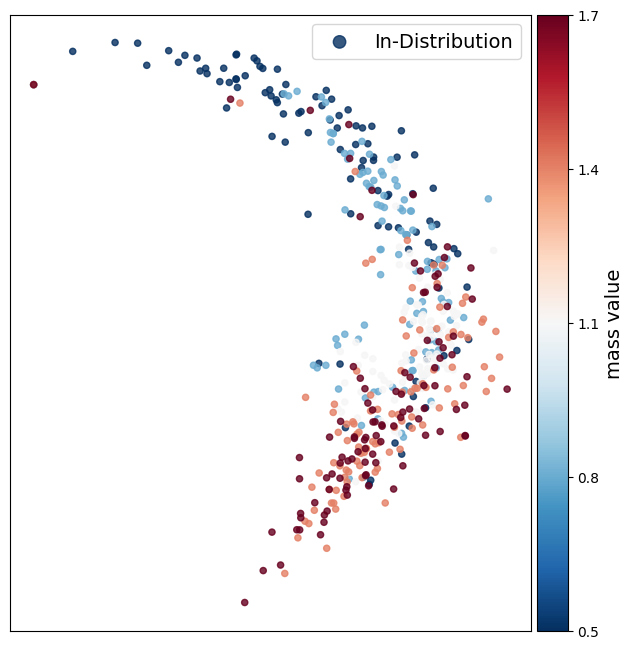

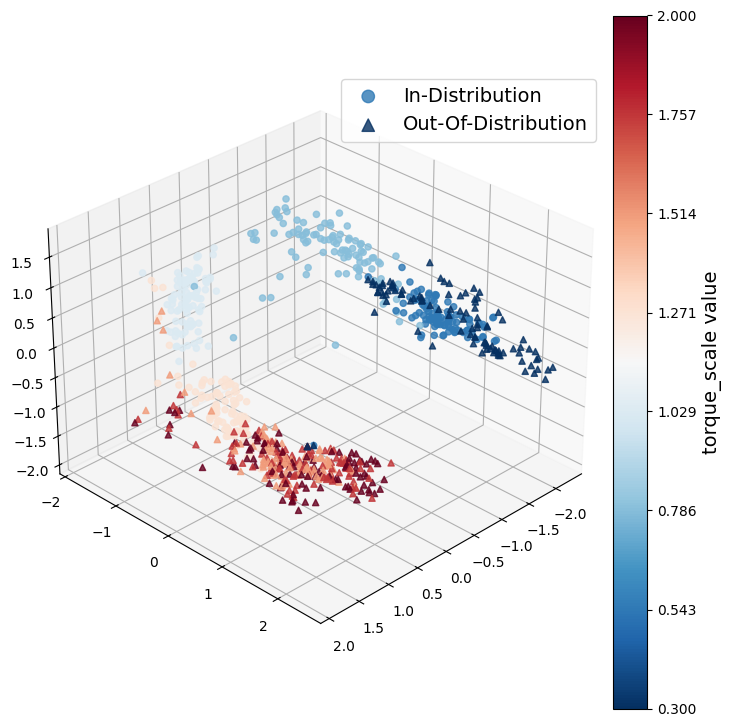

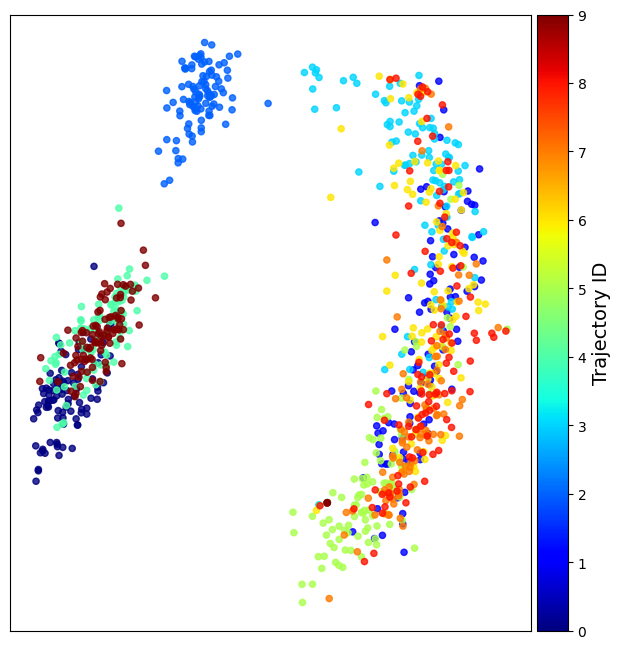

In [19]:
viz = EmbeddingVisualizer(inference_agent)

fig, ax = viz.plot_physics_scan(
    param_name="mass",
    scan_values=np.linspace(0.5, 2.0, 5, endpoint=False).tolist(),
    train_range=(0.5, 2.0),
    projection_method="tsne",
)
# fig.savefig("latent_mass_scan.png", dpi=150, bbox_inches="tight")

fig, ax = viz.plot_physics_scan(
    param_name="torque_scale",
    scan_values=np.linspace(0.3, 2.0, 8).tolist(),
    train_range=(0.5, 1.5),
    projection_method="3d",
)
# fig.savefig("latent_torque_scan.png", dpi=150, bbox_inches="tight")

fig, ax = viz.plot_separation(num_trajs=10, projection_method="pca")
# fig.savefig("latent_separation.png", dpi=150, bbox_inches="tight")

viz.close()